# 08. Model explainability

Explains the headline model (**LightGBM on the `forecast` feature set**, task 3.4.5) with two tools and no extra dependency:

- **TreeSHAP values** computed by LightGBM itself (`pred_contrib=True`). For one forecast they split the prediction into a base value plus one contribution per input, in ug/m3.
- **Permutation importance**: how much the mean absolute error rises on the test days when one input is shuffled.

The model is refitted for every walk-forward block exactly as in notebook 07 and each block's test days are explained, so the explanations describe forecasts made without knowledge of the future. Two views as before: `observed` (perfect-forecast weather, upper bound, 2020-21 to 2024-25) and `forecast` (real archived forecasts, from 2024, small sample).

**These are associations that the model learned.** A high contribution of an input means the model uses it to predict PM2.5. It does not show that the input changes PM2.5.

In [1]:
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aeron import explain
from aeron.evaluation import splits
from aeron.models import trees

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
daily = pd.read_csv(
    ROOT / "data" / "processed" / "daily_us_embassy.csv", index_col=0, parse_dates=True
)
blocks = splits.seasonal_blocks(2020, date(2025, 2, 25))
LEADS, VIEWS = (1, 2, 3), ("observed", "forecast")


def make():
    return trees.lightgbm_model("forecast", "lgbm_forecast_weather")


store = {}
for view in VIEWS:
    for lead in LEADS:
        store[(view, lead)] = explain.explain_blocks(daily, make, lead, blocks, view)
print({k: (len(v[0]), v[1].shape[1]) for k, v in store.items()})

{('observed', 1): (1172, 9), ('observed', 2): (1144, 9), ('observed', 3): (1129, 9), ('forecast', 1): (363, 3), ('forecast', 2): (358, 3), ('forecast', 3): (354, 3)}


## 4.2.1 Global explanations

### Most used inputs in winter (mean absolute SHAP value, ug/m3), observed view

In [2]:
def winter_shap(view, lead):
    contrib, _, _ = store[(view, lead)]
    return explain.mean_abs_contribution(
        contrib[contrib["season"] == "winter"].drop(columns=["block", "season"])
    )


top = pd.DataFrame(
    {f"lead {lead}": winter_shap("observed", lead).head(15) for lead in (1, 3)}
)
rank = pd.concat(
    {
        f"lead {lead}": winter_shap("observed", lead).head(15).reset_index()["index"]
        for lead in (1, 3)
    },
    axis=1,
)
print("top 15 inputs by lead (names)")
print(rank.to_string())
print()
print(
    {
        f"lead {lead}": round(float(winter_shap("observed", lead).sum()), 1)
        for lead in LEADS
    },
    "= total mean |SHAP| over all inputs",
)

top 15 inputs by lead (names)
                   lead 1               lead 3
0   hist_day_evening_mean        wxf_wind_mean
1            hist_pm_lag0  hist_pm_roll14_mean
2           wxf_wind_mean         wxf_gust_max
3         wxo_msl_mean_l0      wxo_msl_mean_l0
4              wxf_wind_u            wxf_rain3
5              wxf_wind_v           wxf_wind_u
6     hist_pm_roll14_mean           wxf_wind_v
7              wxf_precip         hist_day_max
8            hist_day_max          wxf_msl_chg
9      hist_pm_roll7_mean       wxf_temp_range
10           wxf_gust_max         time_doy_sin
11         wxf_temp_range         wxf_temp_min
12           hist_pm_lag1      wxo_msl_mean_l1
13      hist_pm_roll7_max         time_doy_cos
14        wxo_msl_mean_l1   hist_pm_roll7_mean

{'lead 1': 39.9, 'lead 2': 42.0, 'lead 3': 40.6} = total mean |SHAP| over all inputs


In [3]:
groups = pd.DataFrame(
    {f"lead {lead}": explain.by_group(winter_shap("observed", lead)) for lead in LEADS}
)
(groups / groups.sum() * 100).round(0)

,lead 1,lead 2,lead 3
PM2.5 history,50.0,34.0,26.0
calendar,3.0,4.0,7.0
forecast weather for the target day,35.0,46.0,50.0
weather observed up to today,13.0,17.0,17.0


Share (%) of the summed mean absolute SHAP values by feature group, winter, observed view.

In [4]:
top15 = pd.concat(
    {f"lead {lead}": winter_shap("observed", lead).head(10).round(2) for lead in LEADS},
    axis=1,
)
top15

,lead 1,lead 2,lead 3
hist_day_evening_mean,6.50,2.25,NaN
hist_pm_lag0,5.37,2.58,NaN
wxf_wind_mean,4.42,4.70,5.20
wxo_msl_mean_l0,1.62,2.31,2.52
wxf_wind_u,1.58,2.10,1.84
wxf_wind_v,1.46,1.44,1.32
hist_pm_roll14_mean,1.44,3.64,3.38
wxf_precip,1.32,NaN,NaN
hist_day_max,1.29,NaN,1.25
hist_pm_roll7_mean,1.16,NaN,NaN


### Permutation importance (rise in winter MAE when the input is shuffled), observed view

In [5]:
def winter_perm(view, lead):
    _, perm, _ = store[(view, lead)]
    cols = [c for c in perm.columns if c.startswith("winter")]
    return perm[cols].mean(axis=1).sort_values(ascending=False)


pd.concat(
    {f"lead {lead}": winter_perm("observed", lead).head(10).round(2) for lead in LEADS},
    axis=1,
)

,lead 1,lead 2,lead 3
hist_day_evening_mean,3.29,0.51,NaN
hist_pm_lag0,1.46,0.49,NaN
wxf_wind_mean,1.36,1.68,2.09
wxf_precip,0.40,0.18,0.25
wxf_wind_u,0.38,0.88,0.76
wxf_temp_range,0.34,0.51,0.46
wxf_gust_max,0.32,0.53,0.86
hist_day_max,0.30,NaN,NaN
wxf_wind_v,0.19,0.24,NaN
wxo_msl_mean_l0,0.15,0.19,0.31


### Do the two rankings agree? (Spearman correlation of importance over all inputs)

In [6]:
rows = []
for view in VIEWS:
    for lead in LEADS:
        a, b = winter_shap(view, lead), winter_perm(view, lead)
        idx = a.index
        rows.append(
            {
                "view": view,
                "lead": lead,
                "spearman": round(a.corr(b.reindex(idx), method="spearman"), 2),
                "top5 overlap": len(set(a.index[:5]) & set(b.index[:5])),
                "top10 overlap": len(set(a.index[:10]) & set(b.index[:10])),
            }
        )
pd.DataFrame(rows).set_index(["view", "lead"])

spearman  top5 overlap  top10 overlap
view     lead                                       
observed 1         0.69             4              8
         2         0.54             2              9
         3         0.44             3              8
forecast 1         0.27             3              6
         2         0.30             1              5
         3         0.34             3              6

### Real-forecast view (winter days from 2024)

In [7]:
pd.concat(
    {f"lead {lead}": winter_shap("forecast", lead).head(10).round(2) for lead in LEADS},
    axis=1,
)

,lead 1,lead 2,lead 3
wxf_wind_mean,8.76,6.14,7.98
hist_day_evening_mean,8.72,2.80,1.25
hist_pm_lag0,4.75,3.08,NaN
wxf_gust_max,2.58,7.67,9.30
wxf_temp_range,2.02,2.40,2.60
hist_pm_roll7_mean,1.97,NaN,NaN
hist_pm_roll14_mean,1.91,4.54,4.07
wxo_msl_mean_l0,1.33,2.17,2.52
wxf_precip,1.33,NaN,NaN
hist_day_max,1.21,NaN,1.67


In [8]:
groups = pd.DataFrame(
    {f"lead {lead}": explain.by_group(winter_shap("forecast", lead)) for lead in LEADS}
)
(groups / groups.sum() * 100).round(0)

,lead 1,lead 2,lead 3
PM2.5 history,45.0,33.0,24.0
calendar,3.0,4.0,6.0
forecast weather for the target day,41.0,49.0,57.0
weather observed up to today,11.0,14.0,13.0


## 4.2.2 Dependence and local explanations

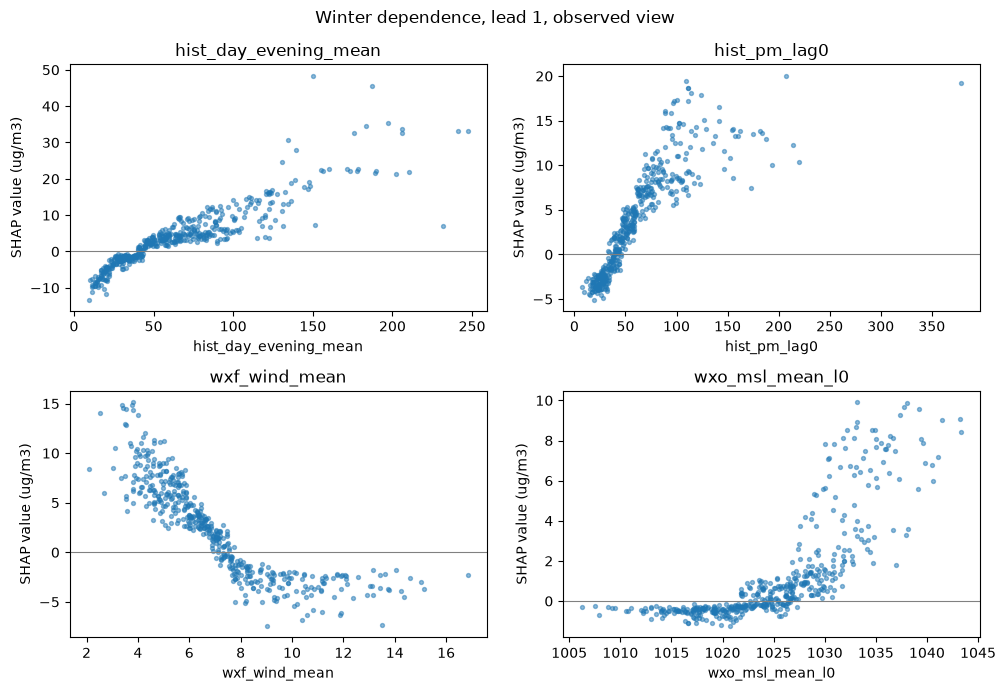

['hist_day_evening_mean', 'hist_pm_lag0', 'wxf_wind_mean', 'wxo_msl_mean_l0']


In [9]:
lead = 1
contrib, _, rows = store[("observed", lead)]
mask = (contrib["season"] == "winter").to_numpy()
top4 = list(winter_shap("observed", lead).index[:4])
top4 = [c for c in top4 if c in rows.columns][:4]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, name in zip(axes.ravel(), top4):
    ax.scatter(rows.loc[mask, name], contrib.loc[mask, name], s=8, alpha=0.5)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel(name)
    ax.set_ylabel("SHAP value (ug/m3)")
    ax.set_title(name)
fig.suptitle("Winter dependence, lead 1, observed view")
fig.tight_layout()
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "reports" / "figures" / "08_dependence_lead1.png", dpi=120)
plt.show()
print(top4)

In [10]:
# How the contribution changes with the value, in plain numbers: median SHAP by fifth of each top input
out = {}
for name in top4:
    q = pd.qcut(rows.loc[mask, name], 5, duplicates="drop")
    out[name] = (
        contrib.loc[mask, name].groupby(q.to_numpy(), observed=True).median().round(1)
    )
for name, s in out.items():
    print(name)
    print(s.to_string())
    print()

hist_day_evening_mean
(9.166, 29.5]        -4.9
(29.5, 46.667]       -1.3
(46.667, 66.733]      3.6
(66.733, 93.867]      5.6
(93.867, 247.167]    13.6

hist_pm_lag0
(7.473, 29.05]       -3.1
(29.05, 43.925]      -0.7
(43.925, 58.675]      3.1
(58.675, 86.375]      7.3
(86.375, 378.667]    11.9

wxf_wind_mean
(2.0780000000000003, 4.91]    7.8
(4.91, 6.009]                 5.8
(6.009, 7.171]                2.6
(7.171, 8.978]               -1.4
(8.978, 16.833]              -3.1

wxo_msl_mean_l0
(1006.253, 1019.019]   -0.5
(1019.019, 1022.973]   -0.4
(1022.973, 1026.569]    0.1
(1026.569, 1030.386]    1.1
(1030.386, 1043.338]    5.7



### Wind direction

The wind components `wxf_wind_u` (east-west) and `wxf_wind_v` (north-south) carry direction. Positive u is wind blowing towards the east, so wind from the west.

In [11]:
wind = ["wxf_wind_mean", "wxf_wind_u", "wxf_wind_v", "wxf_gust_max"]
print("mean |SHAP|, winter, observed view")
print(
    pd.DataFrame(
        {f"lead {lead}": winter_shap("observed", lead).reindex(wind) for lead in LEADS}
    ).round(2)
)
print("mean |SHAP|, winter, real forecasts")
print(
    pd.DataFrame(
        {f"lead {lead}": winter_shap("forecast", lead).reindex(wind) for lead in LEADS}
    ).round(2)
)

mean |SHAP|, winter, observed view
               lead 1  lead 2  lead 3
wxf_wind_mean    4.42    4.70    5.20
wxf_wind_u       1.58    2.10    1.84
wxf_wind_v       1.46    1.44    1.32
wxf_gust_max     0.96    2.54    2.80
mean |SHAP|, winter, real forecasts
               lead 1  lead 2  lead 3
wxf_wind_mean    8.76    6.14    7.98
wxf_wind_u       0.87    1.58    1.72
wxf_wind_v       1.10    1.07    1.02
wxf_gust_max     2.58    7.67    9.30


### Local explanations: three winter days at lead 1 (observed view)

In [12]:
contrib, _, rows = store[("observed", 1)]
rows = rows.reset_index(drop=True)
contrib = contrib.reset_index(drop=True)
w = (rows["season"] == "winter").to_numpy()
pred = contrib.drop(columns=["block", "season"]).sum(axis=1).clip(lower=0)
err = pred - rows["y"]
cases = {
    "highest forecast": int(pred[w].idxmax()),
    "largest underprediction": int(err[w].idxmin()),
    "cleanest observed day": int(rows.loc[w, "y"].idxmin()),
}
for label, i in cases.items():
    c = contrib.drop(columns=["block", "season"]).iloc[i]
    big = c.drop("base_value").reindex(
        c.drop("base_value").abs().sort_values(ascending=False).index
    )[:6]
    print(
        f"{label}: target day {rows.loc[i, 'target_date'].date()}, observed {rows.loc[i, 'y']:.0f}, forecast {pred[i]:.0f}, base value {c['base_value']:.0f}"
    )
    for name, v in big.items():
        val = rows.loc[i, name] if name in rows.columns else float("nan")
        print(f"    {name:28s} value {val:8.2f}   contribution {v:+6.1f}")
    print()

highest forecast: target day 2023-12-14, observed 214, forecast 131, base value 38
    hist_day_evening_mean        value   175.67   contribution  +32.6
    wxo_temp_mean_l0             value   -14.12   contribution  +14.8
    hist_pm_lag0                 value   125.04   contribution  +11.8
    wxf_wind_mean                value     3.93   contribution  +10.2
    wxo_msl_mean_l0              value  1036.40   contribution   +8.2
    hist_day_max                 value   283.00   contribution   +5.2

largest underprediction: target day 2021-11-07, observed 207, forecast 97, base value 38
    hist_pm_lag0                 value   378.67   contribution  +19.2
    hist_day_evening_mean        value   231.50   contribution   +7.0
    wxf_wind_mean                value     5.70   contribution   +5.3
    wxo_msl_mean_l1              value  1035.20   contribution   +3.2
    hist_day_max                 value   725.00   contribution   +2.7
    hist_pm_trend7               value   268.57   contrib

## 4.2.3 Stability across periods

Mean absolute SHAP values per winter, headline model, observed view. Do the same inputs matter in every winter?

In [13]:
def per_winter(lead):
    contrib, _, _ = store[("observed", lead)]
    c = contrib[contrib["season"] == "winter"]
    return (
        c.drop(columns=["season"])
        .groupby("block")
        .apply(lambda g: g.drop(columns=["base_value"]).abs().mean())
    )


for lead in (1, 3):
    pw = per_winter(lead)
    overall = winter_shap("observed", lead)
    top = list(overall.index[:8])
    print(f"lead {lead}: mean |SHAP| of the overall top 8 inputs, by winter")
    print(pw[top].T.round(1).to_string())
    ranks = pw.T.rank(ascending=False)
    print("rank correlation between winters (Spearman):")
    print(pw.T.corr(method="spearman").round(2).to_string())
    topsets = {
        b: set(pw.loc[b].sort_values(ascending=False).index[:10]) for b in pw.index
    }
    names = list(topsets)
    print(
        "top-10 overlap with the next winter:",
        [len(topsets[a] & topsets[b]) for a, b in zip(names[:-1], names[1:])],
    )
    print()

lead 1: mean |SHAP| of the overall top 8 inputs, by winter
block                  winter 2020-21  winter 2021-22  winter 2022-23  winter 2023-24  winter 2024-25
hist_day_evening_mean             3.5             3.6             8.5             7.6             9.4
hist_pm_lag0                      5.3             5.2             6.3             6.1             4.3
wxf_wind_mean                     3.8             2.9             4.2             4.5             6.4
wxo_msl_mean_l0                   3.9             0.9             1.1             0.7             1.6
wxf_wind_u                        2.1             1.7             1.3             1.7             1.1
wxf_wind_v                        1.8             1.3             1.3             1.4             1.4
hist_pm_roll14_mean               1.4             1.0             1.4             1.4             1.9
wxf_precip                        1.2             1.4             1.2             1.4             1.4
rank correlation betwee

Permutation importance per winter (rise in MAE), lead 1, top inputs.

In [14]:
_, perm, _ = store[("observed", 1)]
wcols = [c for c in perm.columns if c.startswith("winter")]
t = list(winter_perm("observed", 1).index[:8])
perm.loc[t, wcols].round(2)

,winter 2020-21,winter 2021-22,winter 2022-23,winter 2023-24,winter 2024-25
hist_day_evening_mean,0.11,1.71,7.04,3.46,4.13
hist_pm_lag0,0.44,1.92,2.70,1.07,1.17
wxf_wind_mean,-0.55,1.13,2.93,1.46,1.82
wxf_precip,-0.17,0.71,0.88,-0.11,0.72
wxf_wind_u,-0.82,0.98,0.95,0.45,0.32
wxf_temp_range,-0.00,0.22,0.86,0.05,0.57
wxf_gust_max,-0.10,0.21,0.44,0.14,0.91
hist_day_max,0.22,0.28,0.51,0.24,0.27


## Saved tables

In [15]:
target = ROOT / "reports" / "model_evaluation"
rows_out = []
for (view, lead), _ in store.items():
    s = winter_shap(view, lead).to_frame("mean_abs_shap")
    s["permutation_gain"] = winter_perm(view, lead).reindex(s.index)
    s["group"] = [explain.group_of(n) for n in s.index]
    s = s.reset_index(names="input")
    s.insert(0, "lead", lead)
    s.insert(0, "view", view)
    rows_out.append(s)
pd.concat(rows_out).round(4).to_csv(target / "importance_winter.csv", index=False)
print("saved importance_winter.csv")

saved importance_winter.csv
